# 02 · Results — forecasting accuracy, explainability and inventory value

Reads the artifacts of the latest completed pipeline run (`artifacts/runs/<id>`).
Every number here is reproducible with `demand-engine run-all`.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in notebooks/; run everything relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

from demand_engine.pipelines.artifacts import latest_run

run = latest_run(Path("artifacts"))
manifest = run.load_json("manifest")
print("run", run.run_id, "| champion:", manifest["champion"], "| test from", manifest["test_start"])
pd.Series(manifest["headline"]).round(4)

run 20261016T142658 | champion: lightgbm | test from 2016-02-29


champion_test_wrmsse          0.8339
baseline_test_wrmsse          0.8695
champion_val_wrmsse           0.7991
savings_vs_rule_pct          76.8220
savings_vs_ma_pct             0.7879
fill_rate_forecast_driven     0.9860
fill_rate_rule_of_thumb       0.8424
dtype: float64

## 1. Forecast accuracy (lower WRMSSE is better)

,rank,model,wrmsse,mae,bias,coverage,seconds
7,1,lightgbm,0.8339,1.1086,-0.0414,0.8675,123.3303
8,2,ets,0.8646,1.1369,-0.0260,0.8549,99.5786
9,3,tsb,0.8685,1.1503,-0.0139,0.6742,3.6008
10,4,moving_average,0.8695,1.1519,-0.0421,0.6807,3.2346
11,5,croston,0.8873,1.2179,0.0627,0.7123,20.0343
12,6,seasonal_naive,1.1187,1.3570,-0.0422,0.7699,3.2432
13,7,naive,1.2454,1.5685,0.3781,0.7601,3.1783


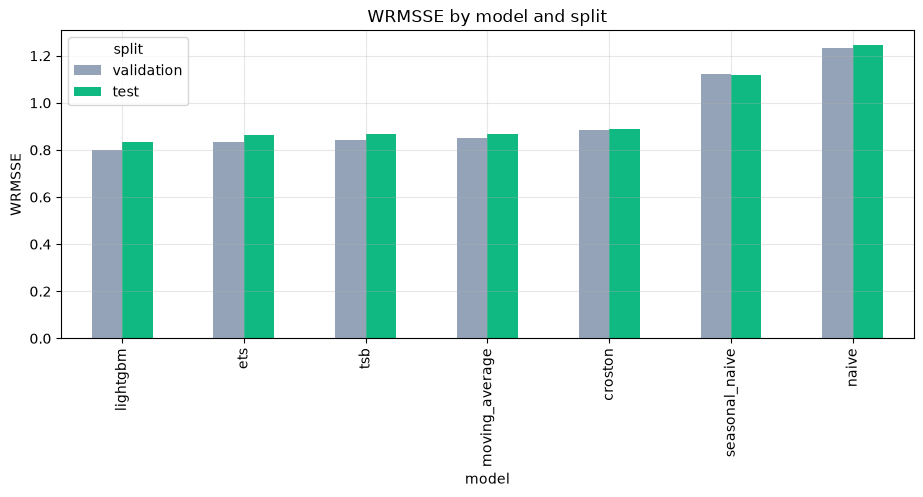

In [2]:
board = run.load_frame("leaderboard")
table = board.pivot(index="model", columns="split", values="wrmsse").sort_values("validation")
ax = table[["validation", "test"]].plot.bar(color=["#94a3b8", "#10b981"], title="WRMSSE by model and split")
ax.set_ylabel("WRMSSE")
board[board["split"] == "test"][["rank", "model", "wrmsse", "mae", "bias", "coverage", "seconds"]].round(4)

The champion is chosen on **validation** folds only; the test split confirms the ranking
out of sample. Coverage close to 0.80 means the 80 % prediction intervals are calibrated.

## 2. What drives the forecast? (SHAP)

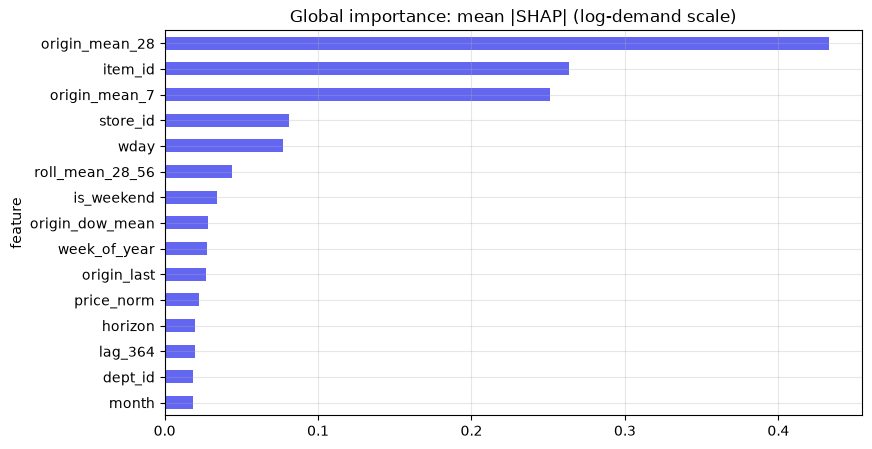

In [3]:
shap_global = run.load_frame("shap_global").head(15).iloc[::-1]
ax = shap_global.plot.barh(x="feature", y="mean_abs_shap", color="#6366f1", legend=False,
                           title="Global importance: mean |SHAP| (log-demand scale)", figsize=(9, 5))

## 3. Inventory value — simulation on unseen demand

,total_cost,fill_rate,avg_inventory_value,n_orders,savings_vs_baseline_pct
policy,,,,,
rule_of_thumb,279773.559,0.842,54869.696,14674,0.000
ma_safety_stock,65360.932,0.986,390024.151,3083,76.638
forecast_driven,64845.947,0.986,386723.672,3075,76.822


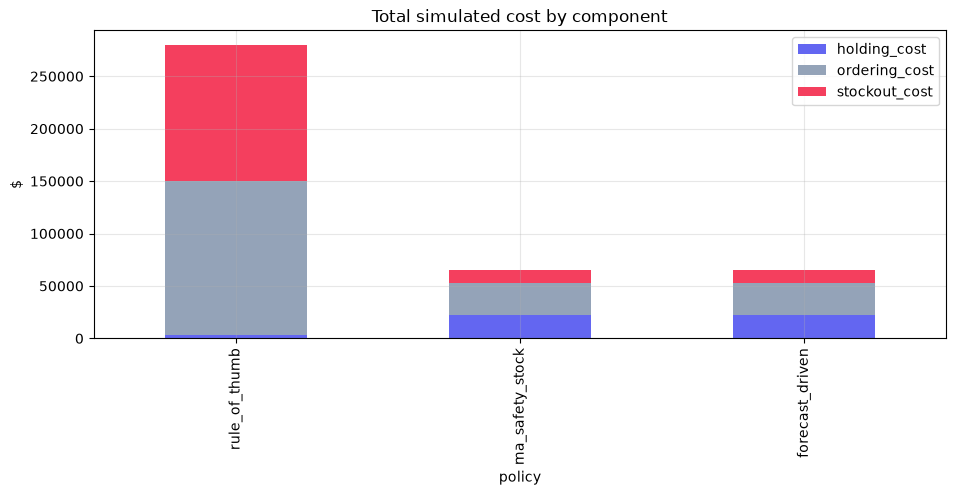

In [4]:
port = run.load_frame("portfolio").set_index("policy")
ax = port[["holding_cost", "ordering_cost", "stockout_cost"]].plot.bar(stacked=True, color=["#6366f1", "#94a3b8", "#f43f5e"],
                                                                         title="Total simulated cost by component")
ax.set_ylabel("$")
port[["total_cost", "fill_rate", "avg_inventory_value", "n_orders", "savings_vs_baseline_pct"]].round(3)

service_level
0.80    5.12
0.85    2.20
0.90    1.59
0.95    0.79
0.97    0.38
0.99    0.25
Name: ML saving vs MA (%), dtype: float64

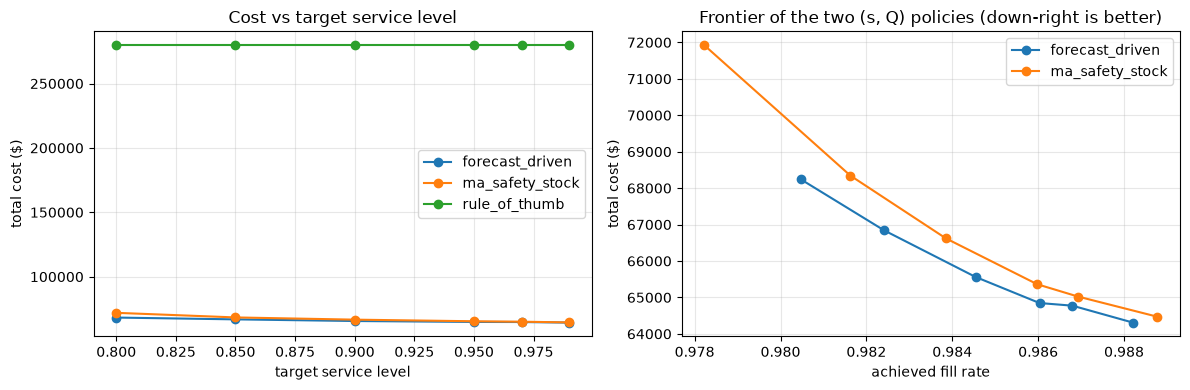

In [5]:
sens = run.load_frame("sensitivity")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for policy, g in sens.groupby("policy"):
    axes[0].plot(g["service_level"], g["total_cost"], marker="o", label=policy)
    if policy != "rule_of_thumb":  # zoom on the two forecast-driven policies
        axes[1].plot(g["fill_rate"], g["total_cost"], marker="o", label=policy)
axes[0].set(xlabel="target service level", ylabel="total cost ($)", title="Cost vs target service level")
axes[1].set(xlabel="achieved fill rate", ylabel="total cost ($)",
            title="Frontier of the two (s, Q) policies (down-right is better)")
axes[0].legend(); axes[1].legend(); plt.tight_layout()
wide = sens.pivot(index="service_level", columns="policy", values="total_cost")
(100 * (wide["ma_safety_stock"] - wide["forecast_driven"]) / wide["ma_safety_stock"]).round(2).rename("ML saving vs MA (%)")

**Reading the results**

* *Rule of thumb → MA + safety stock* isolates the value of **inventory optimisation**
  (statistical safety stock + EOQ instead of fixed cover days).
* *MA + safety stock → forecast-driven* isolates the value of **better forecasts**: both use
  exactly the same policy, costs and lot sizes; only the forecast behind the reorder point differs.
* The frontier plot compares policies at equal service — the fair way to compare inventory policies.